# League-wide situation effects (step 0.36)

Which v1 situations change results across the league, and by how much? This notebook measures each situation value against a fair baseline. Every value comes with its number of games (n), a 95% confidence interval and a test corrected for multiple comparisons. A pre-registered rule then turns the evidence into a verdict for each of the 13 registry rows: **feature**, **keep as a filter**, or **trim**.

Every rule here was fixed before any estimate ran. They are in `docs/decisions.md`, "Analysis rules, set before any effect is estimated" (step 0.34) and its amendment (step 0.36). In brief:

- **Games:** finished regular-season games from 1999 to 2025 (6,967); EPA from 2016 (2,639). 2020 is left out of the venue comparison only.
- **Team-level situations** (venue, rest, time-zone travel, body clock, spread role) can differ between the two teams.
  - They are measured **head-to-head**: only games where exactly one team has the value, one row per game (that team's).
  - That row is compared with the average for its venue that season.
- **Game-level situations** (roof, surface, temperature, precipitation, wind, time slot, primetime, opponent type) are the same for both teams, so the league's win % in them is 50% by construction. They are measured on scoring:
  - total points against the season's average;
  - over % against the league's.
- **Shared values:** short rest, long haul and pick'em are almost always true of both teams. They are measured like game-level situations, on the games where both teams share them.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from pipeline.analysis import (
    EPA_FIRST_SEASON,
    FIGURES_DIR,
    FIRST_SEASON,
    GRID,
    LAST_SEASON,
    SERIES,
    SURFACE,
    TEXT_PRIMARY,
    TEXT_SECONDARY,
    bh_adjust,
    bucket_mean,
    chart_style,
    leave_one_out_strength,
    read_mart,
    regular_season,
    resample_weights,
    save_figure,
    stratum_means,
    summarize,
    win_score,
)

chart_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 150)
pd.set_option("display.max_colwidth", 60)

situations = read_mart("situations").set_index("key")
# The 13 situations the analysis covered, as pre-registered. Step 0.39 added rest_advantage to the
# registry afterwards, and trimmed three of these from v1 (in_v1), which doesn't change the analysis.
PHASE3_SITUATIONS = ["venue", "roof", "surface", "temperature", "precipitation", "wind", "time_slot",
                     "primetime", "rest", "time_zone_travel", "body_clock", "opponent_type", "spread_role"]
situations = situations.loc[PHASE3_SITUATIONS]
situations[["label", "category", "level", "column_name", "value_list"]]

,label,category,level,column_name,value_list
key,,,,,
venue,Venue,venue,team,venue,home|away|neutral
roof,Roof,stadium,game,roof_type,outdoors|dome|retractable_open|retractable_closed
surface,Surface,stadium,game,surface_type,grass|turf
temperature,Temperature,weather,game,temperature_bucket,32_or_below|33_to_50|51_to_79|80_or_above
precipitation,Precipitation,weather,game,precipitation_bucket,none|light_rain|heavy_rain|snow
wind,Wind,weather,game,wind_bucket,under_10|10_to_14|15_plus
time_slot,Time slot,schedule,game,time_slot,tnf|sunday_early|sunday_late|snf|mnf|saturday|other
primetime,Primetime,schedule,game,is_primetime,true|false
rest,Rest,schedule,team,rest_bucket,short|normal|extra|bye


## The statistics, in plain English

**Standard error (SE).** Replay the same seasons and a few lucky bounces would change who won, so any average wobbles from one replay to the next. The standard error is the typical size of that wobble. It shrinks as games are added: four times the games halves it.

**95% confidence interval (CI).** The estimate plus or minus about two standard errors (1.96, exactly). Intervals built this way contain the true value in 95 replays out of 100. If snow games read "−6 to +1 points", the data can't tell a big drop from none; "−6 to −2" would be a real drop.

**Bootstrap.** Instead of a formula, the data supply the wobble.
- Draw 6,967 games at random from our 6,967, with replacement, so some games appear twice and some not at all.
- Recompute every number on that draw, baselines included.
- Do that 2,000 times. The spread of the 2,000 answers is the standard error.

Resampling whole games keeps each game's two mirrored rows together, so nothing is treated as independent when it isn't.

**p-value.** If the situation made no difference, how often would chance alone give an estimate at least this far from zero? A p-value of 0.01 means once in 100 replays. A small p-value is evidence that an effect is real, not proof.

**Multiple comparisons and Benjamini–Hochberg (BH).** Test 90 things at the 5% level and about 4 or 5 will look "significant" by luck alone. BH fixes this in three steps:
1. Rank the 90 p-values from smallest to largest.
2. Give each its own bar: the k-th smallest must be at most 5% × k / 90.
3. Everything up to the last one that clears its bar counts as a discovery.

That keeps the expected share of false discoveries among the discoveries at 5% or less.

## The baselines

An effect is a difference from what would have happened anyway. Each kind of situation gets a baseline that removes what isn't the situation.

- **Venue norm (team-level).** Home teams win more, so an away-heavy bucket such as eastbound travel would look bad just for being away. Each team's result is compared with the average result at the same venue that season:
  - for a home side, the home teams' mean;
  - for an away side, its mirror image (every away row mirrors a home row);
  - at a neutral site, 0.
- **Season norm (game-level).** Scoring changes from season to season: 41.6 points a game in 1999, 49.6 in 2020, 46.0 in 2025. Each game's total is compared with its own season's mean, so an era's scoring isn't credited to whatever was common in that era.
- **League over %.** The betting total already prices both teams' offenses. Over % in a bucket is compared with the league's over %, with pushes left out.

## Two more readings of team-level effects (secondary, descriptive)

A raw effect can come from *who* is in the bucket rather than from the situation. Most morning body-clock games are West Coast teams playing at 1 pm Eastern, so a morning effect could just be how good West Coast teams have been. Two adjustments separate the explanations.

- **Strength control.** A team's strength is how much it out-scored opponents in its *other* games that season, after removing home field.
  - Subtracting the gap between the two teams' strengths leaves what the team did beyond what both teams' other games predicted.
  - The game itself is left out of both strengths (leave-one-out). Otherwise a 30-point loss off a bye would lower the team's own strength and hide the bye effect.
- **Margin vs spread.** The spread is the market's forecast of the margin, so margin + spread is the number of points by which a team beat the market. It is compared with the same venue norm.

The reading was fixed before any estimate:
- an effect that **disappears under the strength control** is team composition;
- one that **survives strength but not the spread** is real and already priced in by the market;
- one that **survives both** is real and under-priced.

## The data

`team_games` has two mirrored rows per game. These per-row columns are prepared first:

- `win_vs_even`: +½ for a win, 0 for a tie, −½ for a loss. Its mean is win % minus .500.
- `spread_margin`: the margin plus the team's spread (negative when favoured), i.e. the points by which the team beat the market.
- `net_epa_play`: the offense's EPA per play minus the EPA per play its defense allowed, in this game (2016 on).
- `cover`: 1 if the team covered the spread, 0 if not. A push is left out.
- `venue_sign`: +1 at home, −1 away, 0 at a neutral site. It says how a row's venue norm relates to the home teams' mean.
- `strength_margin`: the margin minus the leave-one-out strength gap.

In [2]:
team_games = regular_season(read_mart("team_games"))
team_games["win_vs_even"] = win_score(team_games["result"]) - 0.5
team_games["spread_margin"] = team_games["margin"] + team_games["team_spread"]
team_games["net_epa_play"] = team_games["epa"] / (team_games["dropbacks"] + team_games["rushes"]) - team_games["def_epa"] / (
    team_games["def_dropbacks"] + team_games["def_rushes"]
)
team_games["cover"] = team_games["ats_result"].map({"cover": 1.0, "no_cover": 0.0})  # a push is NaN: left out
team_games["venue_sign"] = team_games["venue"].map({"home": 1.0, "away": -1.0, "neutral": 0.0})
team_games["is_primetime"] = team_games["is_primetime"].map({True: "true", False: "false"})  # the registry's spelling

# Strength: the venue-adjusted margin in the team's other games that season (leave-one-out).
home_mean_margin = team_games[team_games["venue"] == "home"].groupby("season")["margin"].mean()
team_games["venue_adjusted_margin"] = team_games["margin"] - team_games["venue_sign"] * team_games["season"].map(home_mean_margin)
strength, opponent_strength = leave_one_out_strength(team_games, "venue_adjusted_margin")
team_games["strength_gap"] = strength - opponent_strength
team_games["strength_margin"] = team_games["margin"] - team_games["strength_gap"]

print(f"{len(team_games):,} team-games = {team_games['game_id'].nunique():,} games, {FIRST_SEASON}–{LAST_SEASON} regular seasons")

13,934 team-games = 6,967 games, 1999–2025 regular seasons


A check that the strength gap measures something real: it should agree with the market's own forecast (the spread, negated so that positive means favoured) and track the result. The correlations use one row per game, the home side's.

In [3]:
home_side = team_games[team_games["is_home"]]
pd.DataFrame(
    {
        "strength gap": home_side["strength_gap"],
        "market forecast (−spread)": -home_side["team_spread"],
        "margin": home_side["margin"],
    }
).corr().round(2)

,strength gap,market forecast (−spread),margin
strength gap,1.00,0.76,0.43
market forecast (−spread),0.76,1.00,0.43
margin,0.43,0.43,1.00


## One row per game

`games` keeps the designated home team's row of each game. At a non-neutral site that's also the row the venue norms average. Game-level numbers come from it too:
- the total;
- the over/under result;
- both offenses' EPA (its `epa` is the home offense, its `def_epa` the away offense).

In [4]:
games = team_games[team_games["is_home"]].set_index("game_id").sort_index()
games["total_points"] = games["points_for"] + games["points_against"]
games["over"] = games["total_result"].map({"over": 1.0, "under": 0.0})  # a push is NaN: left out
games["epa_play"] = (games["epa"] + games["def_epa"]) / (games["dropbacks"] + games["rushes"] + games["def_dropbacks"] + games["def_rushes"])
assert len(games) == team_games["game_id"].nunique()
games[["total_points", "over", "epa_play"]].describe().round(3)

,total_points,over,epa_play
count,6967.000,6868.000,2639.000
mean,44.163,0.495,0.005
std,14.135,0.500,0.141
min,3.000,0.000,-0.467
25%,34.000,0.000,-0.089
50%,44.000,0.000,0.007
75%,53.000,1.000,0.101
max,106.000,1.000,0.466


## Measuring every value

`measure(first_season)` returns one row per situation value and metric, with n, the estimate, its SE, the 95% CI and the p-value. It runs once on 1999–2025 (the pre-registered range) and once on 2016–2025 (the robustness check).

**How the bootstrap is computed.**
- `resample_weights` makes a (2,001 × games) array. Row 0 counts every game once: the actual data. Each other row counts how often each game was drawn in one resample.
- A mean over a resample is then a weighted mean. The baselines are weighted means too, so they are recomputed in every resample.
- `bucket_mean` returns all 2,001 versions of a number at once. `summarize` takes row 0 as the estimate and the spread of the other 2,000 as the standard error.

**Each value has a role:**
- `tested`: in the Benjamini–Hochberg family.
- `mirror`: the same games as another value seen from the other side (away is minus home; underdogs are minus favourites). It is shown but not tested twice.
- `shared`: short rest, long haul and pick'em, measured on the games both teams share, like game-level values.
- `n only`: a neutral site, where both teams are neutral, so the result is even by construction.

In [5]:
TEAM_METRICS = {  # metric: the team_games column it averages
    "win_pct": "win_vs_even",
    "margin": "margin",
    "strength_margin": "strength_margin",
    "spread_margin": "spread_margin",
    "net_epa": "net_epa_play",
    "cover_pct": "cover",  # raw, as the site shows it
}
GAME_METRICS = {  # metric: the games column it averages
    "total_points": "total_points",
    "over_pct": "over",
    "epa": "epa_play",
    "open_air_total": "total_points",  # weather values only: against other open-air games
}
PERCENT = {"win_pct", "cover_pct", "over_pct"}  # reported in percentage points
SHARED = {"rest": "short", "time_zone_travel": "long_haul_4_plus", "spread_role": "pickem"}
MIRRORS = {("venue", "away"): "home", ("spread_role", "underdog"): "favourite", ("spread_role", "big_underdog"): "big_favourite"}
N_ONLY = {("venue", "neutral")}


def one_hot(seasons: pd.Series) -> np.ndarray:
    """A (games × seasons) 0/1 array: which season each game is in."""
    return pd.get_dummies(seasons).to_numpy(dtype=float)


def measure(first_season: int = FIRST_SEASON) -> pd.DataFrame:
    """Every situation value's effect on every metric, for the regular seasons first_season..LAST_SEASON."""
    tg = team_games[team_games["season"] >= first_season]
    g = games[games["season"] >= first_season]
    n_games = len(g)
    position = pd.Series(np.arange(n_games), index=g.index)  # game_id -> column in the weights array
    weights = resample_weights(n_games)
    by_season, pooled = one_hot(g["season"]), np.ones((n_games, 1))
    home_venue = (g["venue"] == "home").to_numpy()  # False at a neutral site

    def column(name):
        return g[name].to_numpy(dtype=float)

    # Venue norms: the home sides' mean per season (an away side's norm is its mirror; a neutral site's is 0).
    venue_norm = {}
    for metric, name in TEAM_METRICS.items():
        if metric != "cover_pct":
            values = column(name)
            venue_norm[metric] = stratum_means(weights, values, home_venue & np.isfinite(values), by_season)
    # Game-level norms: each season's mean total and EPA/play, the league's over %, and open-air games' mean total.
    game_norm = {
        "total_points": (stratum_means(weights, column("total_points"), np.ones(n_games, bool), by_season), by_season),
        "over_pct": (stratum_means(weights, column("over"), np.isfinite(column("over")), pooled), pooled),
        "epa": (stratum_means(weights, column("epa_play"), np.isfinite(column("epa_play")), by_season), by_season),
        "open_air_total": (stratum_means(weights, column("total_points"), g["temperature_bucket"].notna().to_numpy(), by_season), by_season),
    }

    rows = []

    def record(key, value, role, measured_as, metric, in_bucket, values, sign=None, norm=None, strata=None):
        ok = in_bucket & np.isfinite(values)
        stats = summarize(bucket_mean(weights, values, ok, sign, norm, strata))
        scale = 100 if metric in PERCENT else 1
        for k in ("estimate", "se", "ci_low", "ci_high"):
            stats[k] *= scale
        if metric == "cover_pct":
            stats["p"] = np.nan  # a raw rate, not tested
        rows.append({"situation": key, "value": value, "role": role, "measured_as": measured_as, "metric": metric, "n": int(ok.sum()), **stats})

    def game_bucket(key, value, role, in_bucket):
        for metric, name in GAME_METRICS.items():
            if metric == "open_air_total" and situations.loc[key, "category"] != "weather":
                continue
            norm, strata = game_norm[metric]
            record(key, value, role, "game", metric, in_bucket, column(name), np.ones(n_games), norm, strata)

    for key, situation in situations.iterrows():
        name = situation["column_name"]
        for value in situation["value_list"].split("|"):
            if situation["level"] == "game":
                game_bucket(key, value, "tested", (g[name] == value).to_numpy())
                continue

            # Team-level: the games where this value is on one side, or on both.
            has = tg[tg[name] == value]
            if key == "venue":
                has = has[has["season"] != 2020]  # 2020 is left out of venue comparisons
            sides_per_game = has.groupby("game_id").size()
            if SHARED.get(key) == value or (key, value) in N_ONLY:
                both = position[sides_per_game.index[sides_per_game == 2]].to_numpy()
                in_bucket = np.zeros(n_games, bool)
                in_bucket[both] = True
                if (key, value) in N_ONLY:
                    rows.append({"situation": key, "value": value, "role": "n only", "measured_as": "game", "metric": "games", "n": len(both)})
                else:
                    game_bucket(key, value, "shared", in_bucket)
                continue

            role = "mirror" if (key, value) in MIRRORS else "tested"
            sides = has[has["game_id"].map(sides_per_game) == 1].set_index("game_id")
            columns = position[sides.index].to_numpy()
            in_bucket = np.zeros(n_games, bool)
            in_bucket[columns] = True
            sign = np.zeros(n_games)
            sign[columns] = sides["venue_sign"].to_numpy()
            for metric, source in TEAM_METRICS.items():
                values = np.full(n_games, np.nan)
                values[columns] = sides[source].to_numpy(dtype=float)
                if key == "venue" or metric == "cover_pct":  # venue is the baseline itself, so it's measured raw
                    record(key, value, role, "head_to_head", metric, in_bucket, values)
                else:
                    record(key, value, role, "head_to_head", metric, in_bucket, values, sign, venue_norm[metric], by_season)

    return pd.DataFrame(rows)


effects = measure(FIRST_SEASON)
recent = measure(EPA_FIRST_SEASON)
print(f"{len(effects)} estimates for {FIRST_SEASON}–{LAST_SEASON}, {len(recent)} for {EPA_FIRST_SEASON}–{LAST_SEASON}")

204 estimates for 1999–2025, 204 for 2016–2025


### The bootstrap agrees with the formula where a formula applies

The home margin is a plain average over one row per game, with no estimated baseline. Here the textbook standard error, SD / √n, should match the bootstrap's.

In [6]:
home = team_games[(team_games["venue"] == "home") & (team_games["season"] != 2020)]
formula_se = home["margin"].std() / np.sqrt(len(home))
bootstrap_se = effects.query("situation == 'venue' and value == 'home' and metric == 'margin'")["se"].item()
print(f"home margin over {len(home):,} games: formula SE {formula_se:.3f}, bootstrap SE {bootstrap_se:.3f}")

home margin over 6,648 games: formula SE 0.179, bootstrap SE 0.181


## Multiple comparisons: the Benjamini–Hochberg family

The primary tests form the family:
- win % and margin for each tested team-level value;
- total points and over % for each game-level and shared value.

Their thresholds were fixed in advance:
- **Practical size:** 3 points of win % or 1 point of margin; 2 points of total or 5 points of over %.
- **Discovery:** BH-adjusted p ≤ 0.05.
- **Inside the band:** the whole 95% CI lies within ± the practical size.

In [7]:
PRIMARY = {"head_to_head": ["win_pct", "margin"], "game": ["total_points", "over_pct"]}
PRACTICAL = {"win_pct": 3.0, "margin": 1.0, "total_points": 2.0, "over_pct": 5.0}


def flag_family(frame: pd.DataFrame) -> pd.DataFrame:
    """Mark the primary tests, adjust their p-values with BH and compare them with the practical sizes."""
    frame = frame.copy()
    is_primary = np.array([metric in PRIMARY.get(how, []) for metric, how in zip(frame["metric"], frame["measured_as"])])
    frame["primary"] = frame["role"].isin(["tested", "shared"]) & is_primary
    family = frame[frame["primary"]]
    threshold = family["metric"].map(PRACTICAL)
    frame.loc[family.index, "p_adj"] = bh_adjust(family["p"])
    frame.loc[family.index, "practical"] = family["estimate"].abs() >= threshold
    frame.loc[family.index, "inside_band"] = (family["ci_low"] >= -threshold) & (family["ci_high"] <= threshold)
    frame["discovery"] = frame["p_adj"] <= 0.05
    return frame


effects = flag_family(effects)
recent = flag_family(recent)
family = effects[effects["primary"]]
assert len(family) == 90, len(family)
print(f"{len(family)} primary tests: {(family['p'] < 0.05).sum()} have p < 0.05 before the correction, {family['discovery'].sum()} are discoveries after it")

90 primary tests: 33 have p < 0.05 before the correction, 25 are discoveries after it


## Team-level results

One row per head-to-head value. The columns, each with its 95% CI:

- **Win % and margin vs the venue norm**: the primary metrics, with their BH-adjusted p-values.
- **Strength-adjusted and spread-adjusted margins**: the two secondary readings.
- **Net EPA/play vs the venue norm**: 2016 on, so with fewer games.
- **Cover %**: raw, as the site will show it.

Venue is measured raw: home win % above .500 and the home margin, without 2020.

In [8]:
VALUE_LABELS = {
    "home": "Home", "away": "Away", "neutral": "Neutral site",
    "outdoors": "Outdoors", "dome": "Dome", "retractable_open": "Retractable roof, open", "retractable_closed": "Retractable roof, closed",
    "grass": "Grass", "turf": "Turf",
    "32_or_below": "32°F or below", "33_to_50": "33–50°F", "51_to_79": "51–79°F", "80_or_above": "80°F or above",
    "light_rain": "Light rain", "heavy_rain": "Heavy rain", "snow": "Snow",
    "under_10": "Under 10 mph", "10_to_14": "10–14 mph", "15_plus": "15+ mph",
    "tnf": "Thursday night", "sunday_early": "Sunday early", "sunday_late": "Sunday late", "snf": "Sunday night",
    "mnf": "Monday night", "saturday": "Saturday", "other": "Other days and times",
    "true": "Primetime", "false": "Not primetime",
    "short": "Short (5 days or less)", "normal": "Normal (6–8 days)", "extra": "Extra (9–12 days)", "bye": "Off a bye (13+ days)",
    "eastbound_1_3": "East, 1–3 zones", "westbound_1_3": "West, 1–3 zones", "long_haul_4_plus": "4+ zones",
    "morning": "Morning (before noon)", "afternoon": "Afternoon (noon–3:59)", "late_afternoon": "Late afternoon (4–6:59)", "night": "Night (7 pm or later)",
    "divisional": "Divisional", "conference": "Same conference", "non_conference": "Other conference",
    "big_favourite": "Favoured by 7+", "favourite": "Favoured by 3–6.5", "pickem": "Pick'em (spread under 3)",
    "underdog": "Underdog by 3–6.5", "big_underdog": "Underdog by 7+",
}
SPECIFIC_LABELS = {
    ("precipitation", "none"): "Dry",
    ("time_zone_travel", "none"): "No zone change",
    ("rest", "short"): "Both teams on short rest",
    ("time_zone_travel", "long_haul_4_plus"): "Both teams 4+ zones from home",
    ("spread_role", "pickem"): "Pick'em games (spread under 3)",
}


def label(key: str, value: str) -> str:
    return SPECIFIC_LABELS[(key, value)] if (key, value) in SPECIFIC_LABELS else VALUE_LABELS[value]


def interval(frame: pd.DataFrame, metric: str, digits: int = 1) -> pd.Series:
    """'+1.2 [+0.4, +2.0]' for each row's metric."""
    rows = frame[frame["metric"] == metric].set_index(["situation", "value"])
    return rows.apply(lambda r: f"{r['estimate']:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]", axis=1)


def p_adjusted(frame: pd.DataFrame, metric: str) -> pd.Series:
    rows = frame[frame["metric"] == metric].set_index(["situation", "value"])
    return rows["p_adj"].map(lambda p: "" if pd.isna(p) else f"{p:.3f}")


team = effects[(effects["measured_as"] == "head_to_head")]
team_index = team[team["metric"] == "margin"].set_index(["situation", "value"])
team_table = pd.DataFrame(
    {
        "role": team_index["role"],
        "games": team_index["n"],
        "win % vs norm": interval(team, "win_pct"),
        "p adj (win)": p_adjusted(team, "win_pct"),
        "margin vs norm": interval(team, "margin"),
        "p adj (margin)": p_adjusted(team, "margin"),
        "strength-adjusted": interval(team, "strength_margin"),
        "vs spread": interval(team, "spread_margin"),
        "net EPA/play": interval(team, "net_epa", 3),
        "cover % (raw)": interval(team, "cover_pct"),
    }
).reindex(team_index.index)  # registry order
team_table.index =[f"{situations.loc[k, 'label']}: {label(k, v)}" for k, v in team_table.index]
team_table

,role,games,win % vs norm,p adj (win),margin vs norm,p adj (margin),strength-adjusted,vs spread,net EPA/play,cover % (raw)
Venue: Home,tested,6648,"+6.5 [+5.3, +7.7]",0.000,"+2.4 [+2.0, +2.7]",0.000,"+2.3 [+2.0, +2.6]","+0.1 [-0.2, +0.4]","+0.001 [-0.010, +0.012]","+48.9 [+47.7, +50.1]"
Venue: Away,mirror,6648,"-6.5 [-7.7, -5.3]",,"-2.4 [-2.7, -2.0]",,"-2.3 [-2.6, -2.0]","-0.1 [-0.4, +0.2]","-0.001 [-0.012, +0.010]","+51.1 [+49.9, +52.3]"
Rest: Normal (6–8 days),tested,1329,"-2.0 [-4.6, +0.7]",0.253,"-1.2 [-1.9, -0.4]",0.007,"-0.9 [-1.6, -0.3]","-0.5 [-1.1, +0.2]","-0.022 [-0.043, -0.001]","+49.2 [+46.6, +51.9]"
Rest: Extra (9–12 days),tested,653,"+0.1 [-3.7, +3.8]",0.996,"+1.0 [-0.0, +2.1]",0.145,"+0.4 [-0.6, +1.4]","+0.4 [-0.6, +1.3]","+0.022 [-0.004, +0.049]","+50.7 [+46.8, +54.6]"
Rest: Off a bye (13+ days),tested,735,"+3.4 [-0.2, +6.9]",0.153,"+1.2 [+0.1, +2.2]",0.080,"+1.3 [+0.4, +2.2]","+0.5 [-0.5, +1.4]","+0.016 [-0.017, +0.048]","+50.6 [+47.0, +54.2]"
Time-zone travel: No zone change,tested,4068,"+0.8 [-0.2, +1.7]",0.230,"+0.2 [-0.1, +0.5]",0.376,"+0.1 [-0.2, +0.4]","+0.0 [-0.2, +0.3]","-0.005 [-0.013, +0.004]","+49.4 [+47.9, +50.9]"
"Time-zone travel: East, 1–3 zones",tested,2047,"+0.2 [-1.6, +2.1]",0.872,"+0.1 [-0.4, +0.6]",0.823,"-0.1 [-0.6, +0.4]","-0.1 [-0.6, +0.4]","+0.029 [+0.013, +0.045]","+50.1 [+47.9, +52.3]"
"Time-zone travel: West, 1–3 zones",tested,2030,"-1.8 [-3.6, +0.1]",0.145,"-0.5 [-1.0, +0.1]",0.201,"-0.1 [-0.5, +0.4]","+0.0 [-0.4, +0.5]","-0.020 [-0.036, -0.004]","+51.1 [+48.9, +53.3]"
Body clock: Morning (before noon),tested,684,"-1.9 [-5.4, +1.6]",0.433,"-1.1 [-2.1, -0.0]",0.125,"-1.1 [-2.0, -0.1]","-1.0 [-1.9, -0.1]","+0.019 [-0.012, +0.050]","+48.9 [+45.1, +52.7]"
Body clock: Afternoon (noon–3:59),tested,1487,"+1.7 [-0.6, +4.1]",0.255,"+0.5 [-0.2, +1.2]",0.232,"+0.4 [-0.3, +1.0]","+0.2 [-0.4, +0.9]","-0.000 [-0.021, +0.020]","+49.3 [+46.7, +51.9]"


## Game-level results

One row per game-level value, plus the shared short-rest, long-haul and pick'em games. The columns, each with its 95% CI:

- **Total points vs the season norm and over % vs the league**: the primary metrics, with their BH-adjusted p-values.
- **EPA/play of both offenses vs the season norm**: 2016 on.
- **Weather values only:** the total against other open-air games, which keeps the outdoor-vs-dome difference out of the weather.

In [9]:
game = effects[(effects["measured_as"] == "game") & (effects["role"] != "n only")]
game_index = game[game["metric"] == "total_points"].set_index(["situation", "value"])
game_table = pd.DataFrame(
    {
        "role": game_index["role"],
        "games": game_index["n"],
        "total vs season": interval(game, "total_points"),
        "p adj (total)": p_adjusted(game, "total_points"),
        "over % vs league": interval(game, "over_pct"),
        "p adj (over)": p_adjusted(game, "over_pct"),
        "EPA/play vs season": interval(game, "epa", 3),
        "total vs open-air games": interval(game, "open_air_total"),
    }
).reindex(game_index.index).fillna("")  # registry order; only weather values have an open-air comparison
game_table.index = [f"{situations.loc[k, 'label']}: {label(k, v)}" for k, v in game_table.index]
game_table

,role,games,total vs season,p adj (total),over % vs league,p adj (over),EPA/play vs season,total vs open-air games
Roof: Outdoors,tested,5104,"-0.9 [-1.1, -0.7]",0.000,"-0.5 [-1.3, +0.2]",0.232,"-0.000 [-0.004, +0.003]",
Roof: Dome,tested,1138,"+2.8 [+2.1, +3.6]",0.000,"+2.2 [-0.4, +4.9]",0.201,"-0.007 [-0.020, +0.006]",
"Roof: Retractable roof, open",tested,130,"+2.4 [+0.1, +4.8]",0.116,"-0.3 [-8.7, +8.2]",0.996,"+0.032 [+0.001, +0.064]",
"Roof: Retractable roof, closed",tested,594,"+1.4 [+0.4, +2.4]",0.021,"+0.5 [-3.3, +4.3]",0.872,"+0.004 [-0.009, +0.017]",
Surface: Grass,tested,4051,"-0.9 [-1.2, -0.6]",0.000,"-0.9 [-1.9, +0.1]",0.177,"-0.003 [-0.007, +0.002]",
Surface: Turf,tested,2916,"+1.2 [+0.8, +1.6]",0.000,"+1.2 [-0.1, +2.6]",0.177,"+0.003 [-0.002, +0.009]",
Temperature: 32°F or below,tested,329,"-1.4 [-2.9, +0.2]",0.184,"+1.9 [-3.5, +7.4]",0.632,"-0.031 [-0.056, -0.005]","-0.6 [-2.1, +0.9]"
Temperature: 33–50°F,tested,1286,"-1.2 [-1.9, -0.5]",0.005,"-2.0 [-4.5, +0.5]",0.221,"-0.004 [-0.015, +0.007]","-0.4 [-1.0, +0.3]"
Temperature: 51–79°F,tested,2891,"-0.5 [-0.9, -0.1]",0.032,"-0.4 [-1.8, +1.0]",0.682,"+0.008 [+0.002, +0.015]","+0.3 [-0.1, +0.6]"
Temperature: 80°F or above,tested,536,"-1.0 [-2.1, +0.2]",0.208,"+0.0 [-4.1, +4.1]",0.996,"-0.007 [-0.025, +0.010]","-0.2 [-1.3, +0.9]"


### A caveat on EPA: it can't show home field or roof

EPA measures each play against nflfastR's expected-points model. That model's inputs already include:
- whether the offense is at home;
- the roof type (outdoors, dome or retractable);
- the era.

It has no weather inputs. (Source: the feature list in Ben Baldwin, ["nflfastR EP, WP, CP xYAC, and xPass models"](https://opensourcefootball.com/posts/2020-09-28-nflfastr-ep-wp-and-cp-models/), Open Source Football, 2020.) Three consequences:

- **Home field and domes show little in EPA, by design.** A home team's or a dome game's extra points are already *expected* before the snap, so the EPA columns read close to zero for venue and roof even though the points columns don't.
- **Weather does show in EPA.** The model doesn't know about rain or wind, so their effect stays in each play's EPA.
- **Season adjustment is partly redundant for EPA.** The model already allows for the era. That's harmless.

The cell below shows the home edge sitting outside EPA. It fits a straight line through the home games, margin = a + b × net EPA/play. The intercept a is the margin a home team would have if both offenses were equally efficient per play: about 2 points.

In [10]:
recent_home = home[home["season"] >= EPA_FIRST_SEASON].dropna(subset=["net_epa_play"])
slope, intercept = np.polyfit(recent_home["net_epa_play"], recent_home["margin"], 1)
home_epa = effects.query("situation == 'venue' and value == 'home' and metric == 'net_epa'").iloc[0]
dome = effects.query("situation == 'roof' and value == 'dome'").set_index("metric")
print(f"Home games {EPA_FIRST_SEASON}–{LAST_SEASON} (without 2020), n={len(recent_home):,}: margin = {intercept:+.2f} + {slope:.1f} × net EPA/play")
print(f"Home net EPA/play: {home_epa['estimate']:+.3f} [{home_epa['ci_low']:+.3f}, {home_epa['ci_high']:+.3f}], while the home margin over the same games is {recent_home['margin'].mean():+.2f}")
print(
    f"Domes: total points {dome.loc['total_points', 'estimate']:+.1f} [{dome.loc['total_points', 'ci_low']:+.1f}, {dome.loc['total_points', 'ci_high']:+.1f}], "
    f"EPA/play {dome.loc['epa', 'estimate']:+.3f} [{dome.loc['epa', 'ci_low']:+.3f}, {dome.loc['epa', 'ci_high']:+.3f}]"
)

Home games 2016–2025 (without 2020), n=2,340: margin = +1.92 + 48.7 × net EPA/play
Home net EPA/play: +0.001 [-0.010, +0.012], while the home margin over the same games is +1.97
Domes: total points +2.8 [+2.1, +3.6], EPA/play -0.007 [-0.020, +0.006]


## Verdicts, by the pre-registered rule

For each of the 13 registry rows, over every value measured (tested or shared), both primary metrics:

- **feature**: some value is a discovery after BH *and* at least the practical size;
- **trim**: every value's 95% CI lies inside ± the practical size, so an effect that big has been ruled out;
- **keep** as a filter, not featured: anything else.

Venue and spread role always stay, as the context every other split is read against.

**Strongest evidence** depends on the verdict:
- for a featured situation, the discovery of practical size with the smallest adjusted p-value (the one that earned the feature);
- otherwise, the test with the smallest adjusted p-value.

In [11]:
METRIC_NAMES = {"win_pct": "win %", "margin": "margin", "total_points": "total points", "over_pct": "over %"}
verdict_rows = []
for key, situation in situations.iterrows():
    rows = family[family["situation"] == key]
    earned = rows[rows["discovery"] & rows["practical"]]
    rule = "feature" if len(earned) else "trim" if rows["inside_band"].all() else "keep"
    strongest = (earned if len(earned) else rows).sort_values(["p_adj", "p"]).iloc[0]
    verdict_rows.append(
        {
            "situation": situation["label"],
            "level": situation["level"],
            "values": rows["value"].nunique(),
            "discoveries": int(rows["discovery"].sum()),
            "of practical size": int((rows["discovery"] & rows["practical"]).sum()),
            "strongest evidence": f"{label(key, strongest['value'])}, {METRIC_NAMES[strongest['metric']]} "
            f"{strongest['estimate']:+.1f} [{strongest['ci_low']:+.1f}, {strongest['ci_high']:+.1f}], p adj {strongest['p_adj']:.3f}",
            "rule says": rule,
            "verdict": "stays (context)" if key in ("venue", "spread_role") else rule,
        }
    )
verdicts = pd.DataFrame(verdict_rows).set_index("situation")
verdicts

,level,values,discoveries,of practical size,strongest evidence,rule says,verdict
situation,,,,,,,
Venue,team,1,2,2,"Home, margin +2.4 [+2.0, +2.7], p adj 0.000",feature,stays (context)
Roof,game,4,3,1,"Dome, total points +2.8 [+2.1, +3.6], p adj 0.000",feature,feature
Surface,game,2,2,0,"Grass, total points -0.9 [-1.2, -0.6], p adj 0.000",trim,trim
Temperature,game,4,2,0,"33–50°F, total points -1.2 [-1.9, -0.5], p adj 0.005",keep,keep
Precipitation,game,4,5,4,"Heavy rain, total points -5.1 [-7.0, -3.2], p adj 0.000",feature,feature
Wind,game,3,4,2,"15+ mph, total points -3.8 [-5.0, -2.7], p adj 0.000",feature,feature
Time slot,game,7,1,0,"Sunday early, total points -0.5 [-0.8, -0.2], p adj 0.006",keep,keep
Primetime,game,2,0,0,"Not primetime, total points -0.1 [-0.3, +0.0], p adj 0.230",trim,trim
Rest,team,4,1,1,"Normal (6–8 days), margin -1.2 [-1.9, -0.4], p adj 0.007",feature,feature


## Reading each team-level effect with both adjustments

For each tested team-level value with a raw effect (a venue-adjusted margin whose 95% CI excludes zero), the two adjusted margins decide the reading. An adjusted effect *survives* when its CI still excludes zero on the same side.

| Strength-adjusted | Spread-adjusted | Reading |
| --- | --- | --- |
| disappears | (either) | team composition |
| survives | disappears | real, priced in by the market |
| survives | survives | real and under-priced |

Any other combination is described as it falls. Spread role is chosen by the market from the teams' own results, so its strength reading is circular: it is shown, not classified.

In [12]:
SIDES = {1: "survives", 0: "disappears", -1: "reverses"}


def side(row: pd.Series, direction: float) -> int:
    """+1 if the CI excludes zero on the raw effect's side, -1 if on the other side, 0 if it includes zero."""
    low, high = row["ci_low"] * direction, row["ci_high"] * direction
    lo, hi = min(low, high), max(low, high)
    return 1 if lo > 0 else -1 if hi < 0 else 0


reading_rows = []
tested_team = effects[(effects["measured_as"] == "head_to_head") & (effects["role"] == "tested")]
for (key, value), rows in tested_team.groupby(["situation", "value"], sort=False):
    by_metric = rows.set_index("metric")
    raw = by_metric.loc["margin"]
    direction = np.sign(raw["estimate"])
    strength_side, spread_side = side(by_metric.loc["strength_margin"], direction), side(by_metric.loc["spread_margin"], direction)
    if side(raw, direction) != 1:
        reading = "no raw effect"
    elif key == "spread_role":
        reading = "circular: not classified"
    elif strength_side != 1 and spread_side == 0:
        reading = "team composition"
    elif strength_side == 1 and spread_side == 0:
        reading = "real, priced in"
    elif strength_side == 1 and spread_side == 1:
        reading = "real, under-priced"
    else:
        reading = f"other: strength {SIDES[strength_side]}, spread {SIDES[spread_side]}"
    reading_rows.append(
        {
            "value": f"{situations.loc[key, 'label']}: {label(key, value)}",
            "games": int(raw["n"]),
            "BH discovery": bool(by_metric.loc[["win_pct", "margin"], "discovery"].any()),
            "raw margin": f"{raw['estimate']:+.2f}",
            "strength-adjusted": SIDES[strength_side] if side(raw, direction) == 1 else "",
            "vs spread": SIDES[spread_side] if side(raw, direction) == 1 else "",
            "reading": reading,
        }
    )
readings = pd.DataFrame(reading_rows).set_index("value")
readings

,games,BH discovery,raw margin,strength-adjusted,vs spread,reading
value,,,,,,
Venue: Home,6648,True,+2.36,survives,disappears,"real, priced in"
Rest: Normal (6–8 days),1329,True,-1.19,survives,disappears,"real, priced in"
Rest: Extra (9–12 days),653,False,+1.03,,,no raw effect
Rest: Off a bye (13+ days),735,False,+1.17,survives,disappears,"real, priced in"
Time-zone travel: No zone change,4068,False,+0.17,,,no raw effect
"Time-zone travel: East, 1–3 zones",2047,False,+0.10,,,no raw effect
"Time-zone travel: West, 1–3 zones",2030,False,-0.45,,,no raw effect
Body clock: Morning (before noon),684,False,-1.05,survives,survives,"real, under-priced"
Body clock: Afternoon (noon–3:59),1487,False,+0.54,,,no raw effect


## What the site will show, for comparison

The site's league view will add up `mart_league_splits` over a season range: every team-game, both sides of each game, with no head-to-head selection or baselines. Here it is over the same regular seasons, with 2020 left out of venue as the site's default will be.

Two things in this table are true by construction:
- In a team-level value shared by both teams (short rest, pick'em, normal rest), the win % sits near 50%.
- Game-level values sit at 50% for the same reason, which is why they are compared on scoring.

In [13]:
league = read_mart(
    "mart_league_splits",
    "season_type = 'REG' AND season BETWEEN :first AND :last",
    {"first": FIRST_SEASON, "last": LAST_SEASON},
)
league = league[~((league["situation_key"] == "venue") & (league["season"] == 2020))]
sums = league.groupby(["situation_key", "situation_value"])[
    ["games", "wins", "ties", "points_for", "points_against", "ats_games", "ats_covers", "ats_pushes", "ou_games", "overs", "ou_pushes"]
].sum()
site_view = pd.DataFrame(
    {
        "team-games": sums["games"],
        "win %": 100 * (sums["wins"] + sums["ties"] / 2) / sums["games"],
        "margin": (sums["points_for"] - sums["points_against"]) / sums["games"],
        "total points": (sums["points_for"] + sums["points_against"]) / sums["games"],
        "cover %": 100 * sums["ats_covers"] / (sums["ats_games"] - sums["ats_pushes"]),
        "over %": 100 * sums["overs"] / (sums["ou_games"] - sums["ou_pushes"]),
    }
)
order = [(k, v) for k, s in situations.iterrows() for v in s["value_list"].split("|")]
site_view = site_view.reindex(order)
site_view.index = [f"{situations.loc[k, 'label']}: {label(k, v) if v == 'none' else VALUE_LABELS[v]}" for k, v in site_view.index]
site_view.round(1)

,team-games,win %,margin,total points,cover %,over %
Venue: Home,6648,56.5,2.4,44.0,48.9,49.5
Venue: Away,6648,43.5,-2.4,44.0,51.1,49.5
Venue: Neutral site,126,50.0,0.0,43.1,50.0,46.0
Roof: Outdoors,10208,50.0,0.0,43.2,50.0,48.9
Roof: Dome,2276,50.0,0.0,46.8,50.0,51.7
"Roof: Retractable roof, open",260,50.0,0.0,46.4,50.0,49.2
"Roof: Retractable roof, closed",1188,50.0,0.0,46.7,50.0,50.0
Surface: Grass,8102,50.0,0.0,43.2,50.0,48.6
Surface: Turf,5832,50.0,0.0,45.5,50.0,50.7
Temperature: 32°F or below,658,50.0,0.0,42.8,50.0,51.4


## Robustness: 2016–2025 only

The same primary estimates over the last ten seasons, beside the full range. This is descriptive: the verdicts come from 1999–2025 as pre-registered.

A change of direction only matters for an effect that was real to begin with: an estimate near zero flips sign by chance about half the time. So the summary counts two things among the full-range estimates whose CI excludes zero:
- how many still exclude zero in 2016–2025;
- how many point the other way there.

It also counts the estimates that exclude zero only in the recent seasons.

In [14]:
keys = ["situation", "value", "metric"]
both_ranges = effects[effects["primary"]][keys + ["n", "estimate", "ci_low", "ci_high", "discovery"]].merge(
    recent[recent["primary"]][keys + ["n", "estimate", "ci_low", "ci_high", "discovery"]], on=keys, suffixes=("", "_recent")
)
both_ranges["same direction"] = np.sign(both_ranges["estimate"]) == np.sign(both_ranges["estimate_recent"])
both_ranges["recent CI excludes 0"] = (both_ranges["ci_low_recent"] > 0) | (both_ranges["ci_high_recent"] < 0)
both_ranges["full CI excludes 0"] = (both_ranges["ci_low"] > 0) | (both_ranges["ci_high"] < 0)
robust_view = both_ranges.assign(
    value=[f"{situations.loc[k, 'label']}: {label(k, v)}" for k, v in zip(both_ranges["situation"], both_ranges["value"])],
    full=[f"{e:+.1f} [{lo:+.1f}, {hi:+.1f}] n={n:,}" for e, lo, hi, n in zip(both_ranges["estimate"], both_ranges["ci_low"], both_ranges["ci_high"], both_ranges["n"])],
    recent=[f"{e:+.1f} [{lo:+.1f}, {hi:+.1f}] n={n:,}" for e, lo, hi, n in zip(both_ranges["estimate_recent"], both_ranges["ci_low_recent"], both_ranges["ci_high_recent"], both_ranges["n_recent"])],
)[["value", "metric", "full", "recent", "same direction", "full CI excludes 0", "recent CI excludes 0"]]
real = both_ranges["full CI excludes 0"]
print(
    f"Of the {real.sum()} full-range estimates whose CI excludes zero, {(real & both_ranges['recent CI excludes 0']).sum()} still exclude zero "
    f"in 2016–2025 and {(real & ~both_ranges['same direction']).sum()} point the other way there. "
    f"{(both_ranges['recent CI excludes 0'] & ~real).sum()} estimates exclude zero only in 2016–2025."
)
robust_view.set_index(["value", "metric"])

Of the 33 full-range estimates whose CI excludes zero, 23 still exclude zero in 2016–2025 and 1 point the other way there. 4 estimates exclude zero only in 2016–2025.


full                        recent  same direction  full CI excludes 0  recent CI excludes 0
value                                           metric                                                                                                                            
Venue: Home                                     win_pct          +6.5 [+5.3, +7.7] n=6,648     +5.2 [+3.2, +7.2] n=2,340            True                True                  True
                                                margin           +2.4 [+2.0, +2.7] n=6,648     +2.0 [+1.4, +2.5] n=2,340            True                True                  True
Roof: Outdoors                                  total_points     -0.9 [-1.1, -0.7] n=5,104     -1.0 [-1.3, -0.6] n=1,829            True                True                  True
                                                over_pct         -0.5 [-1.3, +0.2] n=5,026     -0.6 [-1.8, +0.7] n=1,812            True               False                 False
Roof: Dome                                      total_points     +2.8 [+2.1, +3.6] n=1,138       +2.4 [+1.1, +3.7] n=403            True                True                  True
                                                over_pct         +2.2 [-0.4, +4.9] n=1,121       +3.0 [-1.5, +7.6] n=400            True               False                 False
Roof: Retractable roof, open                    total_points       +2.4 [+0.1, +4.8] n=130        +3.9 [-0.1, +7.9] n=50            True                True                 False
                                                over_pct           -0.3 [-8.7, +8.2] n=130      -1.0 [-14.9, +13.0] n=50            True               False                 False
Roof: Retractable roof, closed                  total_points       +1.4 [+0.4, +2.4] n=594       +1.9 [+0.6, +3.2] n=356            True                True                  True
                                                over_pct           +0.5 [-3.3, +4.3] n=590       -0.2 [-5.1, +4.7] n=355           False               False                 False
Surface: Grass                                  total_points     -0.9 [-1.2, -0.6] n=4,051     -1.0 [-1.5, -0.6] n=1,511            True                True                  True
                                                over_pct         -0.9 [-1.9, +0.1] n=3,992     -1.0 [-2.7, +0.6] n=1,498            True               False                 False
Surface: Turf                                   total_points     +1.2 [+0.8, +1.6] n=2,916     +1.4 [+0.8, +2.0] n=1,128            True                True                  True
                                                over_pct         +1.2 [-0.1, +2.6] n=2,876     +1.4 [-0.9, +3.6] n=1,120            True               False                 False
Temperature: 32°F or below                      total_points       -1.4 [-2.9, +0.2] n=329       -3.9 [-6.3, -1.4] n=121            True               False                  True
                                                over_pct           +1.9 [-3.5, +7.4] n=321      -4.0 [-12.9, +5.0] n=120           False               False                 False
Temperature: 33–50°F                            total_points     -1.2 [-1.9, -0.5] n=1,286       -2.0 [-3.1, -0.9] n=488            True                True                  True
                                                over_pct         -2.0 [-4.5, +0.5] n=1,268       -2.7 [-6.8, +1.4] n=482            True               False                 False
Temperature: 51–79°F                            total_points     -0.5 [-0.9, -0.1] n=2,891     -0.1 [-0.7, +0.5] n=1,045            True                True                 False
                                                over_pct         -0.4 [-1.8, +1.0] n=2,843     +0.4 [-1.9, +2.7] n=1,035           False               False                 False
Temperature: 80°F or above                      total_points       -1.0 [-2.1, +0.2] n=536       -0.3 [-2.1, +1.5] n=225            True            

## Charts: one per situation family

One chart per registry category: venue, stadium, weather, schedule, travel and matchup.

- Each row of panels is one situation. Its values are listed with their n.
- Each dot is an estimate with its 95% CI.
- Primary panels:
  - A filled dot is a discovery after the Benjamini–Hochberg correction; a hollow dot is not.
  - The shaded band is the pre-registered practical size.
- EPA/play is secondary, drawn as diamonds.
- In the weather chart, grey diamonds give each weather value's total against other open-air games.

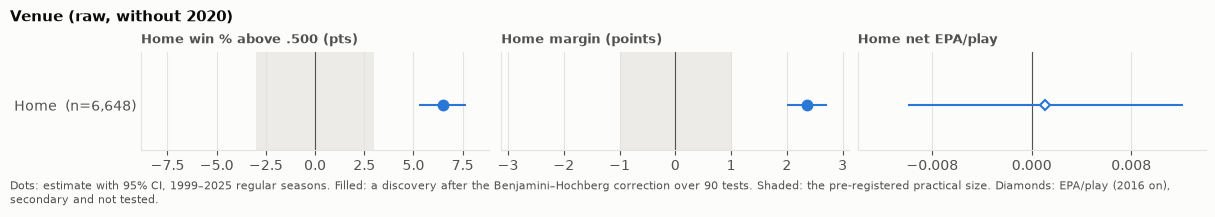

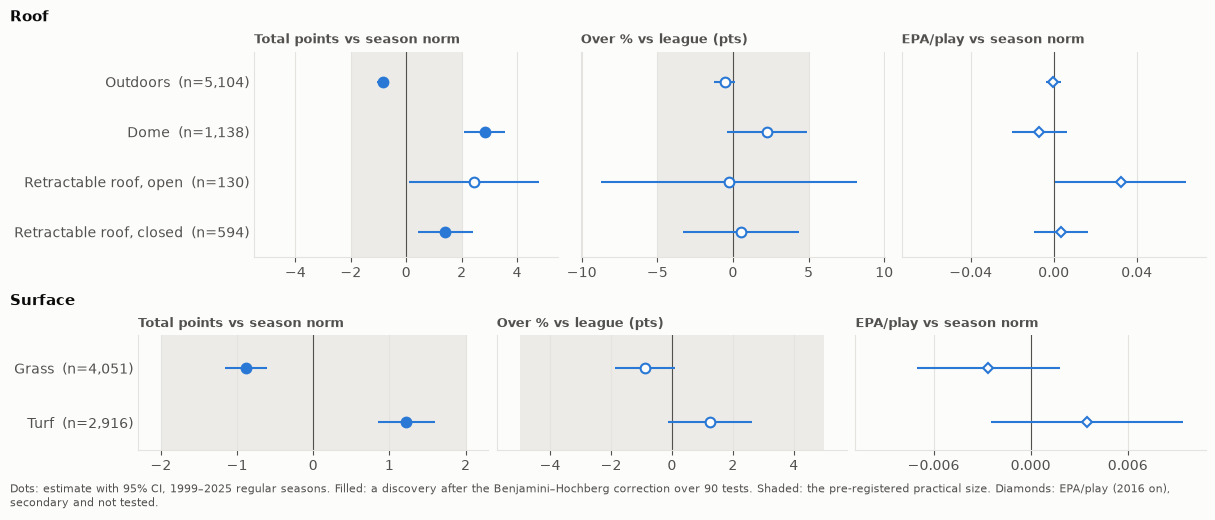

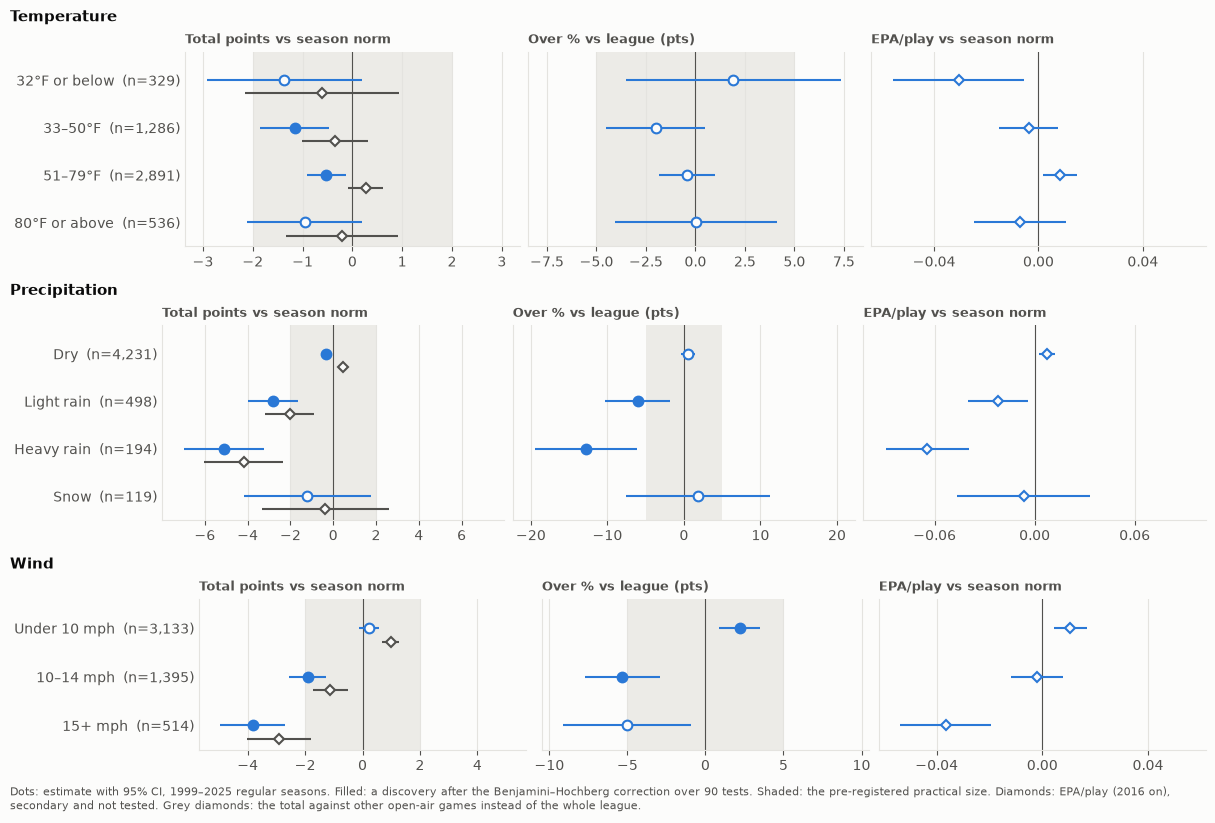

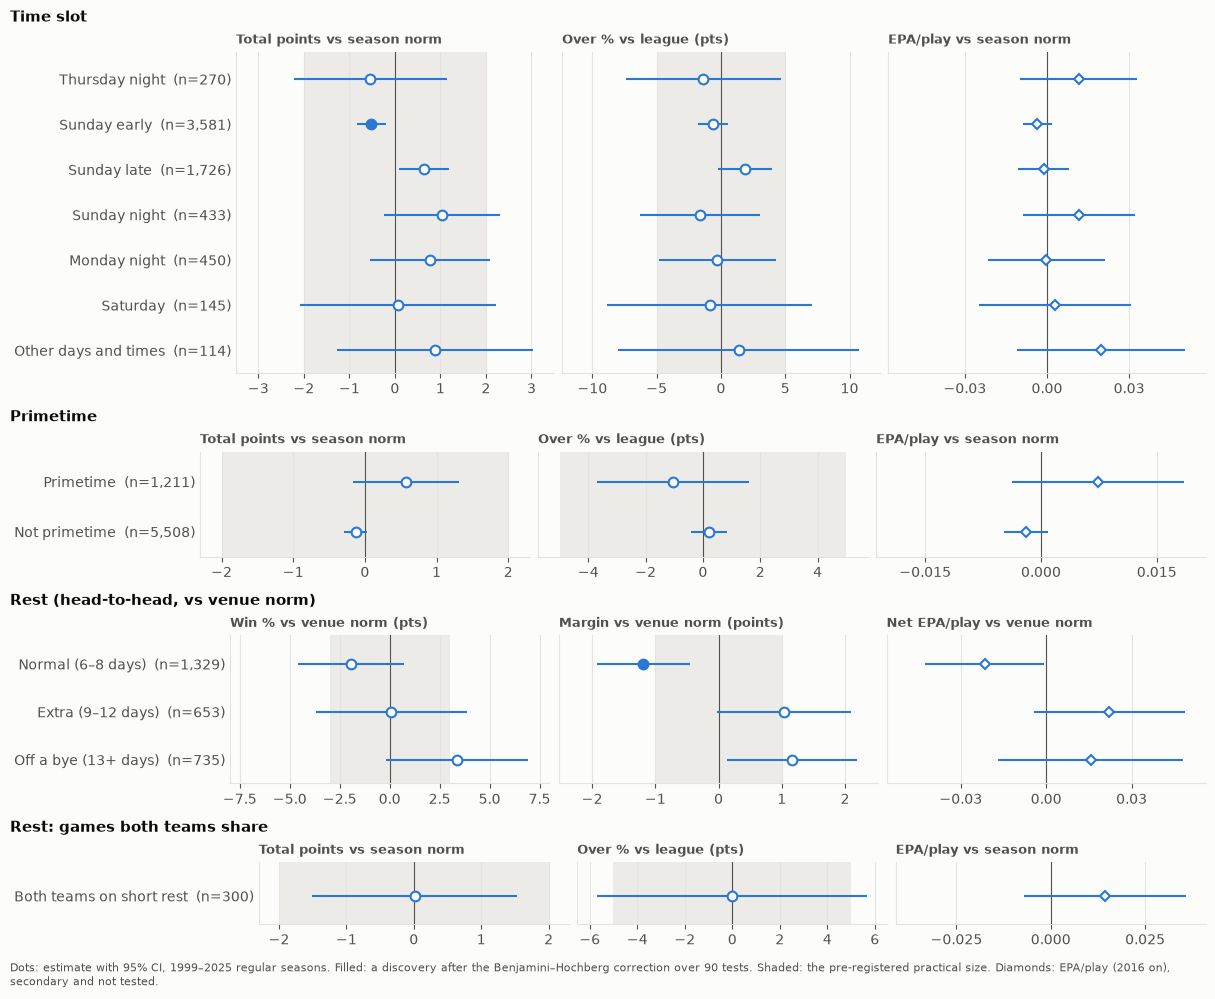

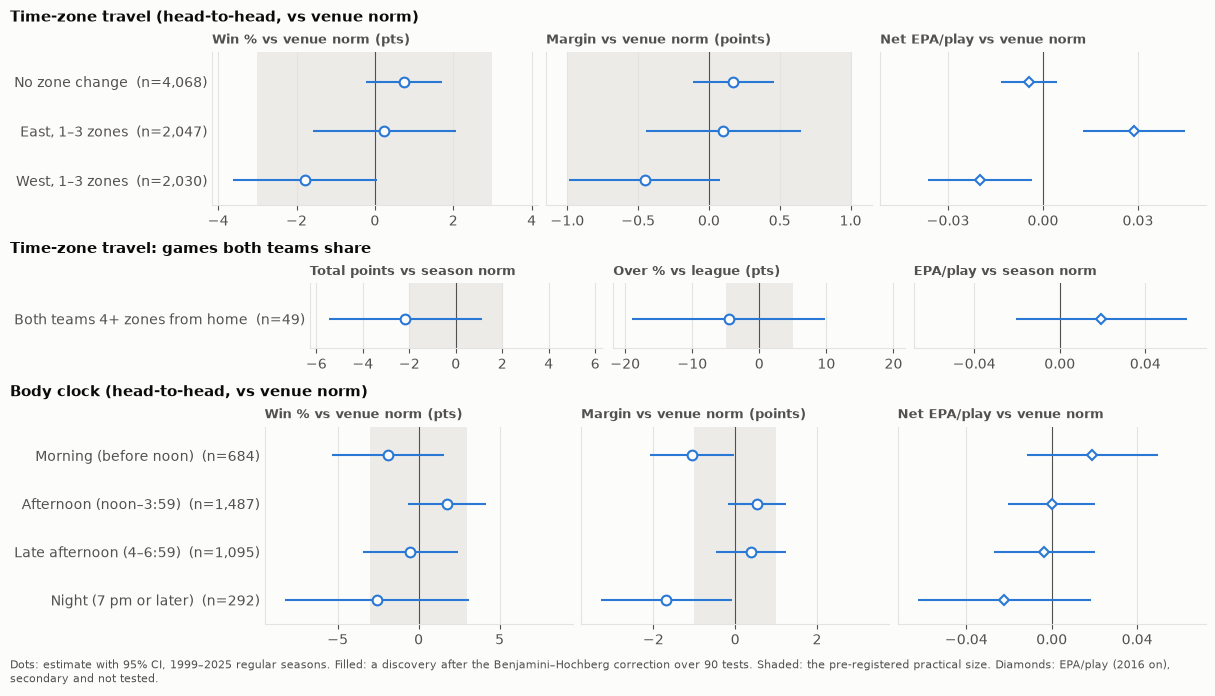

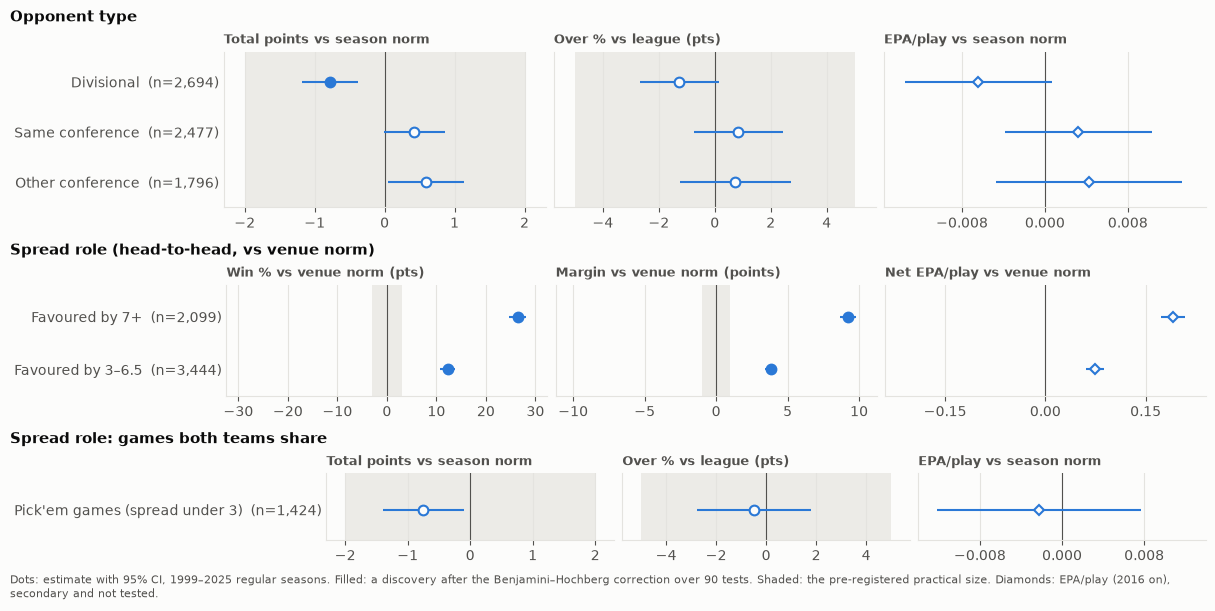

In [15]:
BAND = "#ecebe7"
PANELS = {
    "head_to_head": [("win_pct", "Win % vs venue norm (pts)"), ("margin", "Margin vs venue norm (points)"), ("net_epa", "Net EPA/play vs venue norm")],
    "game": [("total_points", "Total points vs season norm"), ("over_pct", "Over % vs league (pts)"), ("epa", "EPA/play vs season norm")],
}
VENUE_PANELS = [("win_pct", "Home win % above .500 (pts)"), ("margin", "Home margin (points)"), ("net_epa", "Home net EPA/play")]


def blocks_for(category: str) -> list[tuple]:
    """(title, measured_as, key, values) for each row of panels in a category's chart."""
    blocks = []
    for key, situation in situations[situations["category"] == category].iterrows():
        values = situation["value_list"].split("|")
        if situation["level"] == "game":
            blocks.append((situation["label"], "game", key, values))
            continue
        tested = [v for v in values if (key, v) not in MIRRORS and (key, v) not in N_ONLY and SHARED.get(key) != v]
        how = "raw, without 2020" if key == "venue" else "head-to-head, vs venue norm"
        blocks.append((f"{situation['label']} ({how})", "head_to_head", key, tested))
        if key in SHARED:
            blocks.append((f"{situation['label']}: games both teams share", "game", key, [SHARED[key]]))
    return blocks


def draw_point(ax, row, y, primary, color=SERIES[0], marker=None, size=7):
    if row is None or pd.isna(row["estimate"]):
        return
    filled = primary and bool(row["discovery"])
    ax.errorbar(
        row["estimate"], y, xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
        fmt=marker or ("o" if primary else "D"), color=color, markersize=size if primary else size - 1.5,
        markerfacecolor=color if filled else SURFACE, markeredgewidth=1.5, elinewidth=1.5, capsize=0, zorder=3,
    )


def family_chart(category: str):
    blocks = blocks_for(category)
    heights = [len(values) * 0.42 + 0.9 for *_, values in blocks]
    fig = plt.figure(figsize=(12, sum(heights) + 0.4), layout="constrained")
    subfigs = np.atleast_1d(fig.subfigures(len(blocks), 1, height_ratios=heights))
    for subfig, (title, measured_as, key, values) in zip(subfigs, blocks):
        subfig.suptitle(title, x=0.0, ha="left", fontsize=11, fontweight="bold", color=TEXT_PRIMARY)
        panels = VENUE_PANELS if key == "venue" else PANELS[measured_as]
        axes = subfig.subplots(1, len(panels), sharey=True)
        rows = effects[(effects["situation"] == key) & (effects["value"].isin(values)) & (effects["measured_as"] == measured_as)]
        for ax, (metric, panel_title) in zip(axes, panels):
            data = rows[rows["metric"] == metric].set_index("value")
            primary = metric in PRIMARY[measured_as]
            if primary:
                ax.axvspan(-PRACTICAL[metric], PRACTICAL[metric], color=BAND, zorder=0, linewidth=0)
            ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8, zorder=1)
            for y, value in enumerate(values):
                draw_point(ax, data.loc[value] if value in data.index else None, y, primary)
                if metric == "total_points" and category == "weather":
                    open_air = rows[(rows["metric"] == "open_air_total") & (rows["value"] == value)]
                    if len(open_air):
                        draw_point(ax, open_air.iloc[0], y + 0.28, False, color=TEXT_SECONDARY, size=6.5)
            limit = max(1e-9, (data[["ci_low", "ci_high"]].abs().max().max() if len(data) else 0), PRACTICAL.get(metric, 0) if primary else 0) * 1.15
            ax.set_xlim(-limit, limit)
            if not primary:  # EPA/play's small decimals crowd the axis: fewer ticks
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4, symmetric=True))
            ax.set_title(panel_title, fontsize=9, loc="left", color=TEXT_SECONDARY)
            ax.grid(axis="x", visible=True)
            ax.grid(axis="y", visible=False)
            ax.tick_params(axis="y", length=0)
        n = rows[rows["metric"] == PANELS[measured_as][0][0]].set_index("value")["n"]
        axes[0].set_yticks(range(len(values)), [f"{label(key, v)}  (n={n.get(v, 0):,})" for v in values])
        axes[0].set_ylim(len(values) - 0.5, -0.6)
    note = (
        f"Dots: estimate with 95% CI, {FIRST_SEASON}–{LAST_SEASON} regular seasons. Filled: a discovery after the Benjamini–Hochberg correction over 90 tests. "
        "Shaded: the pre-registered practical size. Diamonds: EPA/play (2016 on), secondary and not tested."
    )
    if category == "weather":
        note += " Grey diamonds: the total against other open-air games instead of the whole league."
    fig.text(0.0, -0.01, note, color=TEXT_SECONDARY, fontsize=8, ha="left", va="top", wrap=True)
    return fig


for category in situations["category"].unique():
    fig = family_chart(category)
    save_figure(fig, f"situation_effects_{category}")
    plt.show()

## Chart: the three margins for each team-level value

For each tested team-level value except spread role, whose strength reading is circular, the same margin three ways:
- **Raw:** against the venue norm. For venue, the raw home margin.
- **Strength-adjusted:** after the leave-one-out strength gap.
- **Against the spread:** the venue-adjusted margin vs spread.

In all three panels a filled dot's 95% CI excludes zero, the test the readings use. An asterisk marks a value whose win % or margin is a discovery after the Benjamini–Hochberg correction.

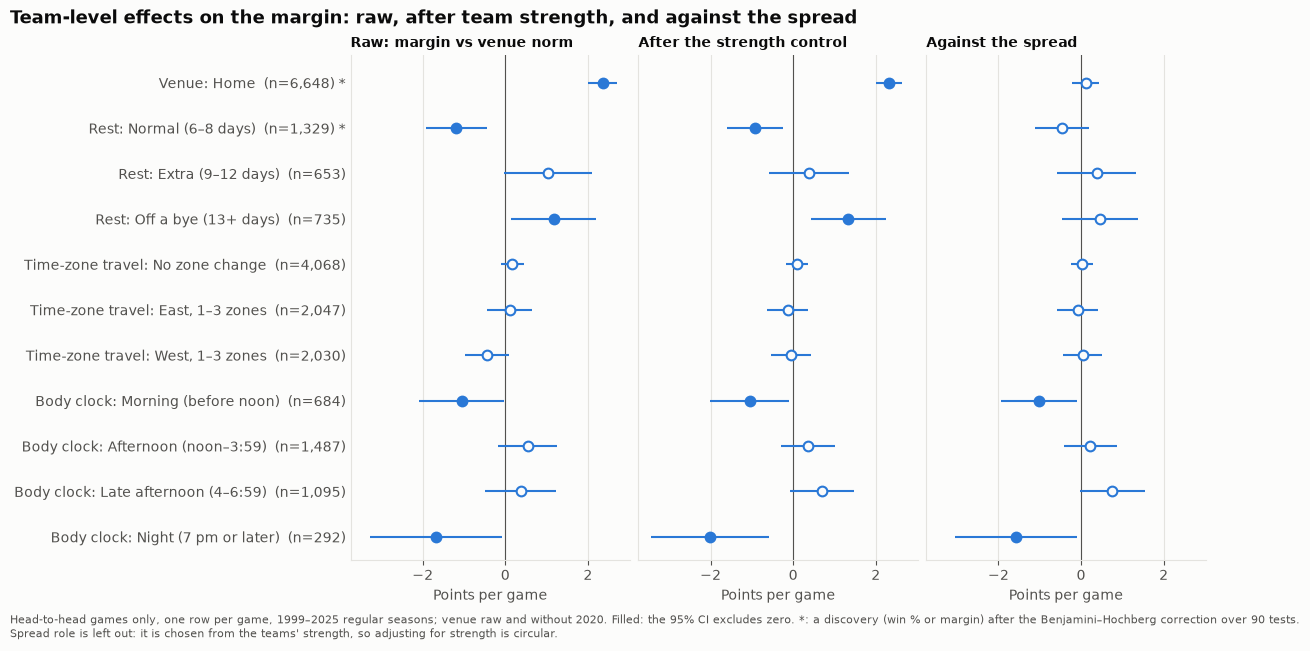

In [16]:
adjusted_rows = tested_team[tested_team["situation"] != "spread_role"]
values = list(dict.fromkeys(zip(adjusted_rows["situation"], adjusted_rows["value"])))
discovered = tested_team[tested_team["metric"].isin(["win_pct", "margin"])].groupby(["situation", "value"])["discovery"].any()
panels = [("margin", "Raw: margin vs venue norm"), ("strength_margin", "After the strength control"), ("spread_margin", "Against the spread")]
fig, axes = plt.subplots(1, 3, figsize=(12, len(values) * 0.42 + 1.4), sharey=True, sharex=True, layout="constrained")
for ax, (metric, title) in zip(axes, panels):
    data = adjusted_rows[adjusted_rows["metric"] == metric].set_index(["situation", "value"])
    ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
    for y, idx in enumerate(values):
        row = data.loc[idx].copy()
        row["discovery"] = (row["ci_low"] > 0) or (row["ci_high"] < 0)  # filled: the CI excludes zero
        draw_point(ax, row, y, True)
    ax.set_title(title, fontsize=10, loc="left", color=TEXT_PRIMARY)
    ax.set_xlabel("Points per game")
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
n = adjusted_rows[adjusted_rows["metric"] == "margin"].set_index(["situation", "value"])["n"]
axes[0].set_yticks(
    range(len(values)),
    [f"{situations.loc[k, 'label']}: {label(k, v)}  (n={n[(k, v)]:,}){' *' if discovered[(k, v)] else ''}" for k, v in values],
)
axes[0].set_ylim(len(values) - 0.5, -0.6)
fig.suptitle("Team-level effects on the margin: raw, after team strength, and against the spread", x=0.0, ha="left", fontsize=13, fontweight="bold")
fig.text(
    0.0, -0.01,
    f"Head-to-head games only, one row per game, {FIRST_SEASON}–{LAST_SEASON} regular seasons; venue raw and without 2020. "
    "Filled: the 95% CI excludes zero. *: a discovery (win % or margin) after the Benjamini–Hochberg correction over 90 tests.\n"
    "Spread role is left out: it is chosen from the teams' strength, so adjusting for strength is circular.",
    color=TEXT_SECONDARY, fontsize=8, ha="left", va="top",
)
save_figure(fig, "team_effects_adjusted")
plt.show()

## Done-when check

The plan's check:
- one chart per situation family, each with error bars;
- every situation's evidence summarised in the verdict table.

The asserts also confirm that the family is the pre-registered 90 tests, and that the row-level data agree with the mart the site will read.

In [17]:
categories = list(situations["category"].unique())
assert sorted(categories) == sorted(["venue", "stadium", "weather", "schedule", "travel", "matchup"]), categories
for category in categories:
    assert (FIGURES_DIR / f"situation_effects_{category}.png").exists()
assert (FIGURES_DIR / "team_effects_adjusted.png").exists()
assert len(family) == 90
assert len(verdicts) == 13 and verdicts["rule says"].isin(["feature", "keep", "trim"]).all()

# The row-level data agree with the mart the site will read: each game-level value's mean total, and the home record.
for key, situation in situations[situations["level"] == "game"].iterrows():
    mean_total = games.groupby(situation["column_name"])["total_points"].mean()
    for value in situation["value_list"].split("|"):
        mart_total = (sums.loc[(key, value), "points_for"] + sums.loc[(key, value), "points_against"]) / sums.loc[(key, value), "games"]
        assert abs(mean_total[value] - mart_total) < 1e-9, (key, value)
home_rows = team_games[(team_games["venue"] == "home") & (team_games["season"] != 2020)]
home_sums = sums.loc[("venue", "home")]
assert abs(100 * (home_rows["win_vs_even"].mean() + 0.5) - 100 * (home_sums["wins"] + home_sums["ties"] / 2) / home_sums["games"]) < 1e-9

print(f"{len(categories)} family charts and the adjustments chart saved; {len(family)} tests; verdicts:")
print(verdicts["verdict"].value_counts().to_string())

6 family charts and the adjustments chart saved; 90 tests; verdicts:
verdict
feature            4
keep               4
trim               3
stays (context)    2
